<a href="https://colab.research.google.com/github/hugolo000/DigitalImage_PROJECT/blob/main/notebooks/07_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 - Classical vs Deep Learning comparison
This notebook puts the two methods side by side on the same test images:
- **Deep learning:** the U-Net of notebook 03 (ResNet34 pretrained on ImageNet + augmentation, same code and settings), retrained here.
- **Classical:** the method of notebook 05 (SLIC superpixels + hand-crafted features + Random Forest), retrained here.

It produces the comparison table and confusion matrices (slide 8), the success and failure examples (slides 9-10), and a robustness test where the test images are degraded (noise, darkness, low contrast).
Needs a **GPU runtime** (Runtime → Change runtime type → T4 GPU).

## 1. Setup and data
Same libraries and same CamVid loading as notebooks 03 and 05.

In [1]:
!pip install -q -U segmentation-models-pytorch albumentations

import time
import zipfile
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage.segmentation import slic
from skimage.feature import local_binary_pattern
from sklearn.ensemble import RandomForestClassifier

import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")   # should print "cuda"

# Download and unzip CamVid
DATASET_URL = "https://github.com/alexgkendall/SegNet-Tutorial/archive/refs/heads/master.zip"
DATA_DIR = Path("./data")
RAW_ZIP_PATH = DATA_DIR / "camvid_raw.zip"
EXTRACTED_DIR = DATA_DIR / "extracted"

DATA_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_ZIP_PATH.exists():
    print("[INFO] Downloading CamVid dataset...")
    urllib.request.urlretrieve(DATASET_URL, RAW_ZIP_PATH)
if not EXTRACTED_DIR.exists():
    print("[INFO] Unzipping dataset files...")
    with zipfile.ZipFile(RAW_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACTED_DIR)

BASE_DIR = (EXTRACTED_DIR / "SegNet-Tutorial-master").resolve()
print("[INFO] Done.")

Device: cuda
[INFO] Downloading CamVid dataset...
[INFO] Unzipping dataset files...
[INFO] Done.


In [2]:
def load_camvid_split(txt_filename, base_dir):
    """Reads a CamVid split file and returns a table with image and mask paths."""
    image_paths, mask_paths = [], []
    with open(base_dir / "CamVid" / txt_filename, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                img_p, mask_p = Path(parts[0]), Path(parts[1])
                img_abs = (base_dir / "CamVid" / img_p.parts[-2] / img_p.parts[-1]).resolve()
                mask_abs = (base_dir / "CamVid" / mask_p.parts[-2] / mask_p.parts[-1]).resolve()
                if img_abs.exists() and mask_abs.exists():
                    image_paths.append(str(img_abs))
                    mask_paths.append(str(mask_abs))
    return pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths})

df_train = load_camvid_split("train.txt", BASE_DIR)
df_val = load_camvid_split("val.txt", BASE_DIR)
df_test = load_camvid_split("test.txt", BASE_DIR)
print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# Same settings as notebooks 03 and 05
IMAGE_SIZE = 256
NUM_CLASSES = 12
VOID_CLASS = 11
CLASS_NAMES = ["Sky", "Building", "Pole", "Road", "Pavement", "Tree",
               "SignSymbol", "Fence", "Car", "Pedestrian", "Bicyclist", "Void"]
CLASS_COLORS = np.array([[128, 128, 128], [128, 0, 0], [192, 192, 128], [128, 64, 128],
                         [60, 40, 222], [128, 128, 0], [192, 128, 128], [64, 64, 128],
                         [64, 0, 128], [64, 64, 0], [0, 128, 192], [0, 0, 0]]) / 255.0
CAMVID_CMAP = ListedColormap(CLASS_COLORS)

def load_pair(row):
    """Reads one image (RGB) and its mask, both resized to 256x256."""
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(mask, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_NEAREST)
    return img, mask

def show_mask(ax, mask, title=""):
    """Displays a class mask with the CamVid colours."""
    ax.imshow(mask, cmap=CAMVID_CMAP, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

# Metric: same confusion-matrix mIoU as notebooks 03 and 05
def update_confusion(confusion, pred, mask):
    valid = mask != VOID_CLASS
    idx = mask[valid].astype(np.int64) * NUM_CLASSES + pred[valid].astype(np.int64)
    confusion += np.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
    return confusion

def miou_from_confusion(confusion):
    intersection = np.diag(confusion).astype(np.float64)
    union = confusion.sum(0) + confusion.sum(1) - intersection
    iou = intersection / np.maximum(union, 1)
    present = union[:VOID_CLASS] > 0
    return iou[:VOID_CLASS][present].mean(), iou

def evaluate(pred_masks, masks):
    """mIoU, IoU per class, pixel accuracy and confusion matrix over a list of masks."""
    confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for p, m in zip(pred_masks, masks):
        confusion = update_confusion(confusion, p, m)
    miou, iou = miou_from_confusion(confusion)
    return miou, iou, np.trace(confusion) / confusion.sum(), confusion

def per_image_miou(pred_masks, masks):
    """mIoU of each image separately (used to pick examples)."""
    out = []
    for p, m in zip(pred_masks, masks):
        conf = update_confusion(np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64), p, m)
        out.append(miou_from_confusion(conf)[0])
    return np.array(out)

# All test images and masks loaded once (used by both methods)
test_images, test_masks = zip(*[load_pair(df_test.iloc[i]) for i in range(len(df_test))])
test_images, test_masks = list(test_images), list(test_masks)
print(f"Loaded {len(test_images)} test images")

Train: 367 | Val: 101 | Test: 233
Loaded 233 test images


## 2. Deep learning method: U-Net (same as notebook 03)
We retrain the main model of notebook 03 with exactly the same settings: U-Net with a ResNet34 encoder pretrained on ImageNet, same augmentation (flip, brightness/contrast, blur), CrossEntropy + Dice loss, Adam (lr = 1e-3), 10 epochs, best model kept on validation loss.
Retraining here gives us the trained model in this notebook, so we can predict any test image (also degraded ones in the robustness test). The score can differ slightly from notebook 03 because training is random.

In [3]:
torch.manual_seed(42)
np.random.seed(42)

def get_train_transforms():
    """Same augmentation pipeline as notebooks 02-03."""
    return A.Compose([
        A.Resize(height=IMAGE_SIZE, width=IMAGE_SIZE),
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

def get_valid_transforms():
    """Validation / test: only resize + ImageNet normalisation."""
    return A.Compose([
        A.Resize(height=IMAGE_SIZE, width=IMAGE_SIZE),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

class CamVidDataset(Dataset):
    """Loads an image and its mask, applies the transforms, returns tensors."""
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image = cv2.cvtColor(cv2.imread(self.df.iloc[idx]["image_path"]), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.df.iloc[idx]["mask_path"], cv2.IMREAD_GRAYSCALE)
        out = self.transform(image=image, mask=mask)
        return out["image"], out["mask"].long()

train_loader = DataLoader(CamVidDataset(df_train, get_train_transforms()), batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(CamVidDataset(df_val, get_valid_transforms()), batch_size=8, shuffle=False, num_workers=2)
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")

Train batches: 46 | Val batches: 13


In [4]:
EPOCHS = 10
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=NUM_CLASSES).to(DEVICE)

# Same loss, optimizer and scheduler as notebook 03
ce_loss = nn.CrossEntropyLoss(ignore_index=VOID_CLASS)
dice_loss = smp.losses.DiceLoss(mode="multiclass", from_logits=True, ignore_index=VOID_CLASS)
def criterion(outputs, masks):
    return ce_loss(outputs, masks) + dice_loss(outputs, masks)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)

valid_tf = get_valid_transforms()
def predict_unet(images, batch_size=16):
    """Predicts the class of every pixel for a list of 256x256 RGB images."""
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch = torch.stack([valid_tf(image=img)["image"] for img in images[i:i + batch_size]]).to(DEVICE)
            preds += list(model(batch).argmax(dim=1).cpu().numpy().astype(np.uint8))
    return preds

val_images, val_masks = zip(*[load_pair(df_val.iloc[i]) for i in range(len(df_val))])
val_images, val_masks = list(val_images), list(val_masks)

best_val_loss = float("inf")
for epoch in range(EPOCHS):
    t0 = time.time()
    # Training
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(images), masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            val_loss += criterion(model(images), masks).item()
    val_loss /= len(val_loader)
    scheduler.step(val_loss)
    val_miou = evaluate(predict_unet(val_images), val_masks)[0]

    print(f"Epoch {epoch + 1}/{EPOCHS} | train loss {train_loss / len(train_loader):.4f} | "
          f"val loss {val_loss:.4f} | val mIoU {val_miou:.4f} ({time.time() - t0:.0f} s)")
    if val_loss < best_val_loss:   # keep the best model, like notebook 03
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_unet.pth")
        print("   -> saved")

# Test with the best model
model.load_state_dict(torch.load("best_unet.pth", map_location=DEVICE))
unet_preds = predict_unet(test_images)
unet_miou, unet_iou, unet_acc, unet_conf = evaluate(unet_preds, test_masks)
print(f"\nU-Net test mIoU = {unet_miou:.4f} | pixel accuracy = {unet_acc:.4f}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/10 | train loss 1.7089 | val loss 1.1783 | val mIoU 0.3858 (12 s)
   -> saved
Epoch 2/10 | train loss 1.0678 | val loss 1.0537 | val mIoU 0.4010 (8 s)
   -> saved
Epoch 3/10 | train loss 0.9639 | val loss 1.0139 | val mIoU 0.4220 (10 s)
   -> saved
Epoch 4/10 | train loss 0.9205 | val loss 0.9667 | val mIoU 0.4192 (10 s)
   -> saved
Epoch 5/10 | train loss 0.8630 | val loss 0.8610 | val mIoU 0.4673 (8 s)
   -> saved
Epoch 6/10 | train loss 0.8061 | val loss 0.8312 | val mIoU 0.4869 (8 s)
   -> saved
Epoch 7/10 | train loss 0.7939 | val loss 1.8845 | val mIoU 0.2599 (9 s)
Epoch 8/10 | train loss 0.8127 | val loss 0.7952 | val mIoU 0.4847 (8 s)
   -> saved
Epoch 9/10 | train loss 0.7524 | val loss 0.7731 | val mIoU 0.5218 (9 s)
   -> saved
Epoch 10/10 | train loss 0.7232 | val loss 0.7073 | val mIoU 0.5607 (10 s)
   -> saved

U-Net test mIoU = 0.4339 | pixel accuracy = 0.8233


## 3. Classical method (same as notebook 05)
SLIC superpixels (400 per image) + 42 hand-crafted features (colour, LBP texture, HOG-style gradients, position) + Random Forest with balanced class weights: the best setting found on validation in notebook 05.

In [5]:
FEATURE_NAMES = (
    [f"{stat}_{ch}" for ch in ["R", "G", "B", "H", "S", "V", "L", "a", "b"] for stat in ["mean", "std"]]
    + [f"LBP_{k}" for k in range(10)]
    + ["grad_mag"] + [f"grad_ori_{k}" for k in range(8)]
    + ["x_mean", "y_mean", "y_top", "y_bottom", "area"]
)
YY, XX = np.mgrid[0:IMAGE_SIZE, 0:IMAGE_SIZE] / IMAGE_SIZE

def superpixel_features(img, seg):
    """42 hand-crafted features per superpixel: colour, texture, gradients, position."""
    n = seg.max() + 1
    flat = seg.ravel()
    counts = np.bincount(flat, minlength=n).astype(np.float64)

    def region_mean(values):
        return np.bincount(flat, weights=values.ravel(), minlength=n) / counts

    feats = []
    # Colour: mean and std in RGB, HSV and Lab
    rgb = img.astype(np.float64) / 255.0
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float64) / [180.0, 255.0, 255.0]
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float64) / 255.0
    for space in (rgb, hsv, lab):
        for c in range(3):
            m = region_mean(space[..., c])
            m2 = region_mean(space[..., c] ** 2)
            feats += [m, np.sqrt(np.maximum(m2 - m ** 2, 0))]
    # Texture: uniform LBP histogram
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    for k in range(10):
        feats.append(region_mean((lbp == k).astype(np.float64)))
    # Gradients (HOG-style): magnitude + orientation histogram
    g = gray.astype(np.float64) / 255.0
    gx = cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    ori_bin = np.minimum((np.mod(np.arctan2(gy, gx), np.pi) / np.pi * 8).astype(int), 7)
    mag_sum = np.bincount(flat, weights=mag.ravel(), minlength=n)
    feats.append(mag_sum / counts)
    for k in range(8):
        feats.append(np.bincount(flat, weights=(mag * (ori_bin == k)).ravel(), minlength=n) / (mag_sum + 1e-6))
    # Position and size
    y_top = np.full(n, np.inf)
    y_bottom = np.full(n, -np.inf)
    np.minimum.at(y_top, flat, YY.ravel())
    np.maximum.at(y_bottom, flat, YY.ravel())
    feats += [region_mean(XX), region_mean(YY), y_top, y_bottom, counts / flat.size]
    return np.stack(feats, axis=1).astype(np.float32)

def superpixel_labels(seg, mask):
    """Majority ground-truth class of each superpixel (void excluded), -1 if only void."""
    n = seg.max() + 1
    hist = np.bincount(seg.ravel() * NUM_CLASSES + mask.ravel().astype(np.int64),
                       minlength=n * NUM_CLASSES).reshape(n, NUM_CLASSES)
    hist[:, VOID_CLASS] = 0
    labels = hist.argmax(axis=1)
    labels[hist.sum(axis=1) == 0] = -1
    return labels

N_SEGMENTS = 400   # best setting from notebook 05

def predict_classical(images):
    """SLIC + features + Random Forest for a list of 256x256 RGB images."""
    preds = []
    for img in images:
        seg = slic(img, n_segments=N_SEGMENTS, compactness=10, start_label=0)
        preds.append(rf.predict(superpixel_features(img, seg))[seg].astype(np.uint8))
    return preds

In [6]:
t0 = time.time()

# Training superpixels
X_list, y_list = [], []
for i in range(len(df_train)):
    img, mask = load_pair(df_train.iloc[i])
    seg = slic(img, n_segments=N_SEGMENTS, compactness=10, start_label=0)
    X_list.append(superpixel_features(img, seg))
    y_list.append(superpixel_labels(seg, mask))
X_train = np.concatenate(X_list)
y_train = np.concatenate(y_list)
keep = y_train >= 0                     # drop void-only superpixels
X_train, y_train = X_train[keep], y_train[keep]

# Random Forest (same settings as notebook 05)
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, max_features="sqrt",
                            class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
print(f"Random Forest trained on {len(y_train)} superpixels ({time.time() - t0:.0f} s)")

# Test
classical_preds = predict_classical(test_images)
cl_miou, cl_iou, cl_acc, cl_conf = evaluate(classical_preds, test_masks)
print(f"Classical test mIoU = {cl_miou:.4f} | pixel accuracy = {cl_acc:.4f}")

Random Forest trained on 116170 superpixels (140 s)
Classical test mIoU = 0.3333 | pixel accuracy = 0.7572


## 4. Comparison on the test set (slide 8)
Both methods are scored on the same 233 test images (256x256), with the same mIoU, pixel accuracy and confusion matrix.

,Method,Test mIoU,Pixel accuracy
0,Classical (SLIC + features + RF),0.3333,0.7572
1,Deep learning (U-Net ResNet34),0.4339,0.8233


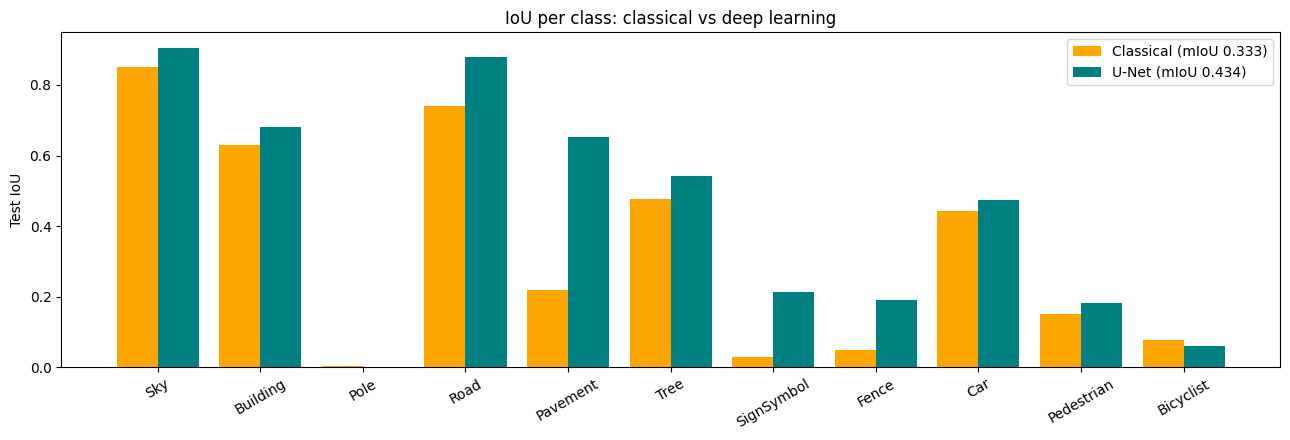

In [7]:
df_compare = pd.DataFrame({
    "Method": ["Classical (SLIC + features + RF)", "Deep learning (U-Net ResNet34)"],
    "Test mIoU": [round(cl_miou, 4), round(unet_miou, 4)],
    "Pixel accuracy": [round(cl_acc, 4), round(unet_acc, 4)],
})
display(df_compare)

# IoU per class, side by side
x = np.arange(VOID_CLASS)
plt.figure(figsize=(13, 4.5))
plt.bar(x - 0.2, cl_iou[:VOID_CLASS], width=0.4, label=f"Classical (mIoU {cl_miou:.3f})", color="orange")
plt.bar(x + 0.2, unet_iou[:VOID_CLASS], width=0.4, label=f"U-Net (mIoU {unet_miou:.3f})", color="teal")
plt.xticks(x, CLASS_NAMES[:VOID_CLASS], rotation=30)
plt.ylabel("Test IoU")
plt.title("IoU per class: classical vs deep learning")
plt.legend()
plt.tight_layout()
plt.show()

Confusion matrices (row-normalised): each row is a true class and shows what its pixels were predicted as. The diagonal is the correct part.

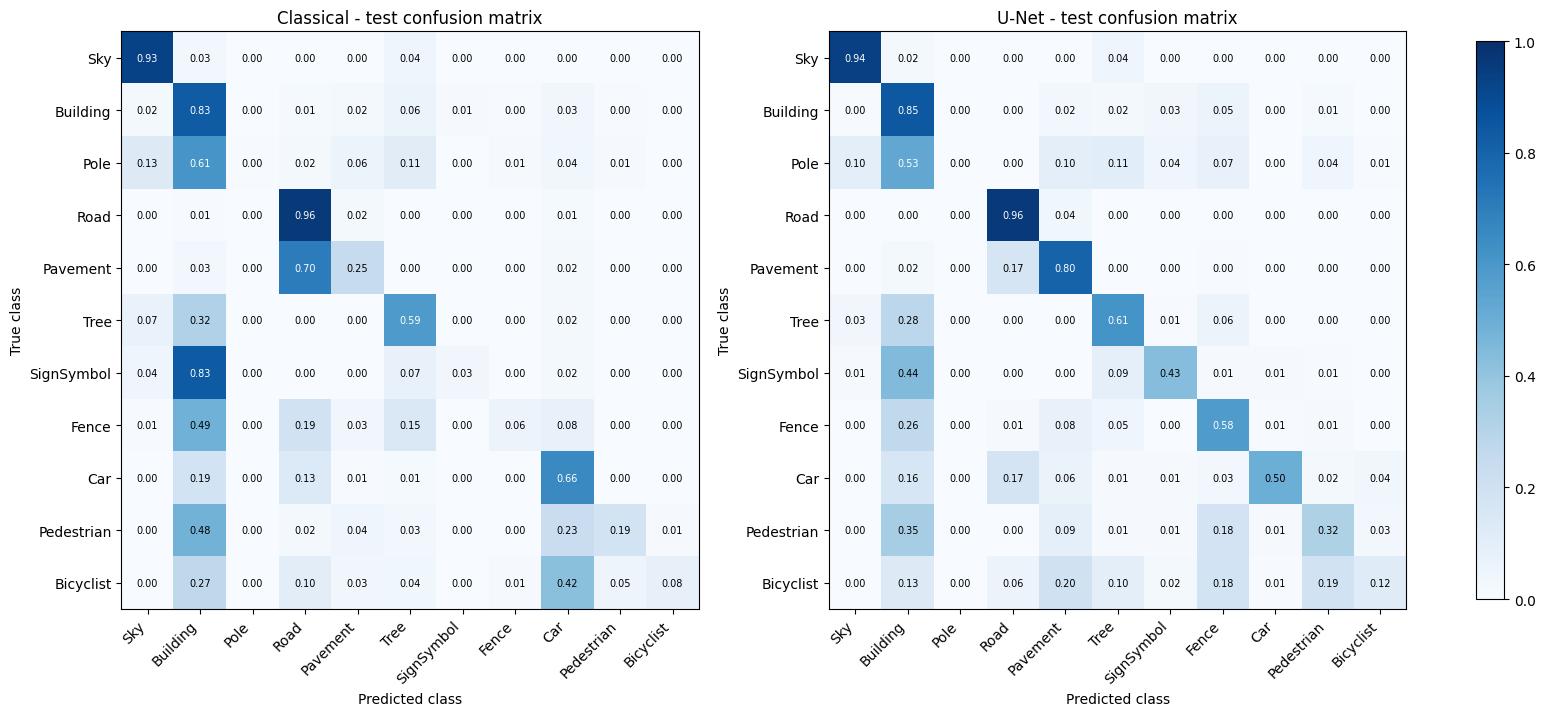

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, conf, title in [(axes[0], cl_conf, "Classical"), (axes[1], unet_conf, "U-Net")]:
    cm = conf[:VOID_CLASS, :VOID_CLASS].astype(np.float64)
    cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(VOID_CLASS)); ax.set_xticklabels(CLASS_NAMES[:VOID_CLASS], rotation=45, ha="right")
    ax.set_yticks(range(VOID_CLASS)); ax.set_yticklabels(CLASS_NAMES[:VOID_CLASS])
    for i in range(VOID_CLASS):
        for j in range(VOID_CLASS):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(f"{title} - test confusion matrix")
plt.colorbar(im, ax=axes, fraction=0.02)
plt.show()

**What we learn from the comparison (slide 8):**
- The U-Net is better overall (mIoU 0.434 vs 0.333, pixel accuracy 0.82 vs 0.76), but not everywhere in the same way.
- **Biggest gain: pavement** (0.22 → 0.65). Pavement predicted as road drops from 70% to 17%: telling them apart needs context (kerb, position next to the road), which the CNN captures and our superpixel features do not. Also clear gains on signs (0.03 → 0.21), fences (0.05 → 0.19) and road (0.74 → 0.88).
- **Similar results** on sky, building, car and pedestrian: for large classes with a typical colour and position, hand-crafted features are almost enough.
- **Poles are at 0 for both methods** and bicyclists are slightly better with the classical method (0.08 vs 0.06). So thin objects are not only a superpixel problem: CamVid images are 480x360 and a pole is only 2-3 pixels wide; after resizing to 256x256 (which also squeezes the 4:3 image into a square) it is about 1-2 pixels wide. This is a limit of the preprocessing shared by both methods.
- **"Building" is the default class for both**: it takes 53% of poles and 35% of pedestrians even with the U-Net.
- Both methods have a large validation → test gap (U-Net 0.56 → 0.43, classical 0.40 → 0.33), consistent with the darker test images found in notebook 06 (checked in section 8).

## 5. Examples on the same images (slides 9-10)
The mIoU is computed for each test image and each method. We show the same images with both predictions:
- **Both work well:** highest mean score of the two methods (slide 9, pros).
- **Where deep learning helps most:** biggest gap between U-Net and classical (slide 9).
- **Worst for the classical method** and **worst for the U-Net** (slide 10, failures and limitations).

Both good        : [np.int64(161), np.int64(62), np.int64(111)]
Biggest DL gain  : [np.int64(73), np.int64(218), np.int64(89)]
Worst classical  : [np.int64(149), np.int64(177), np.int64(182)]
Worst U-Net      : [np.int64(149), np.int64(221), np.int64(181)]


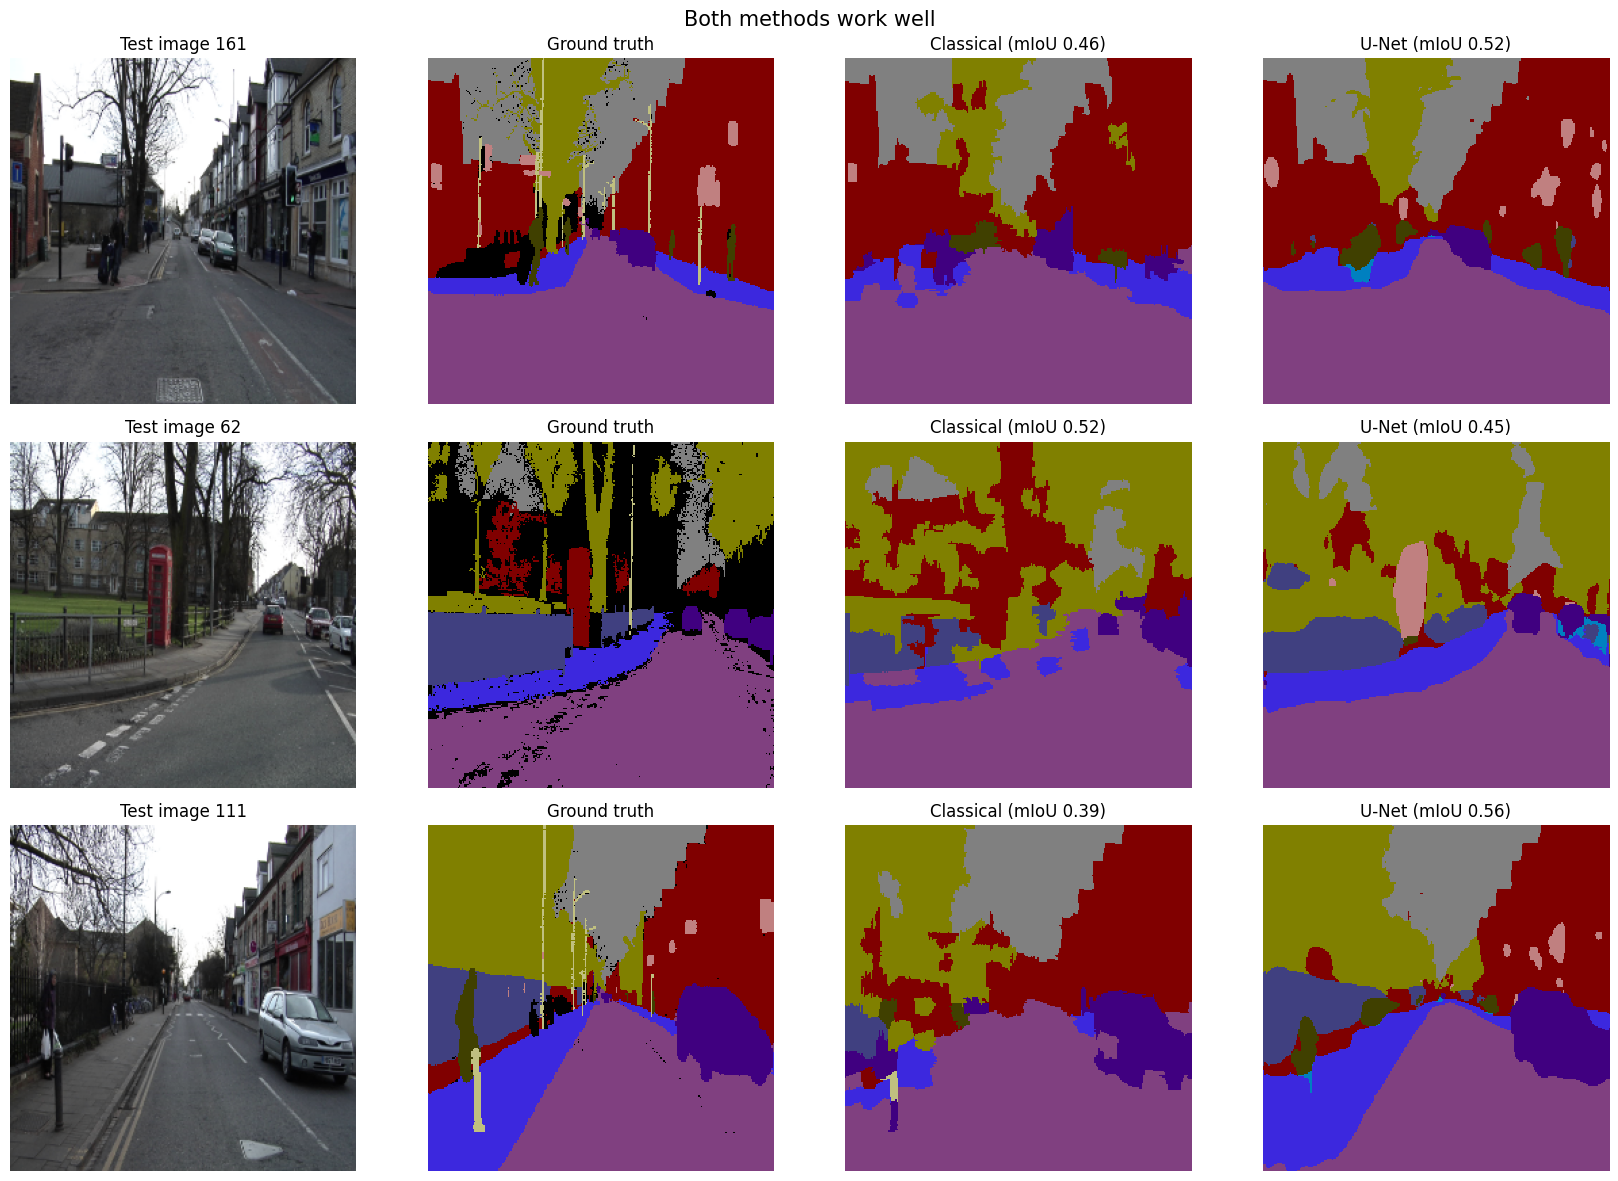

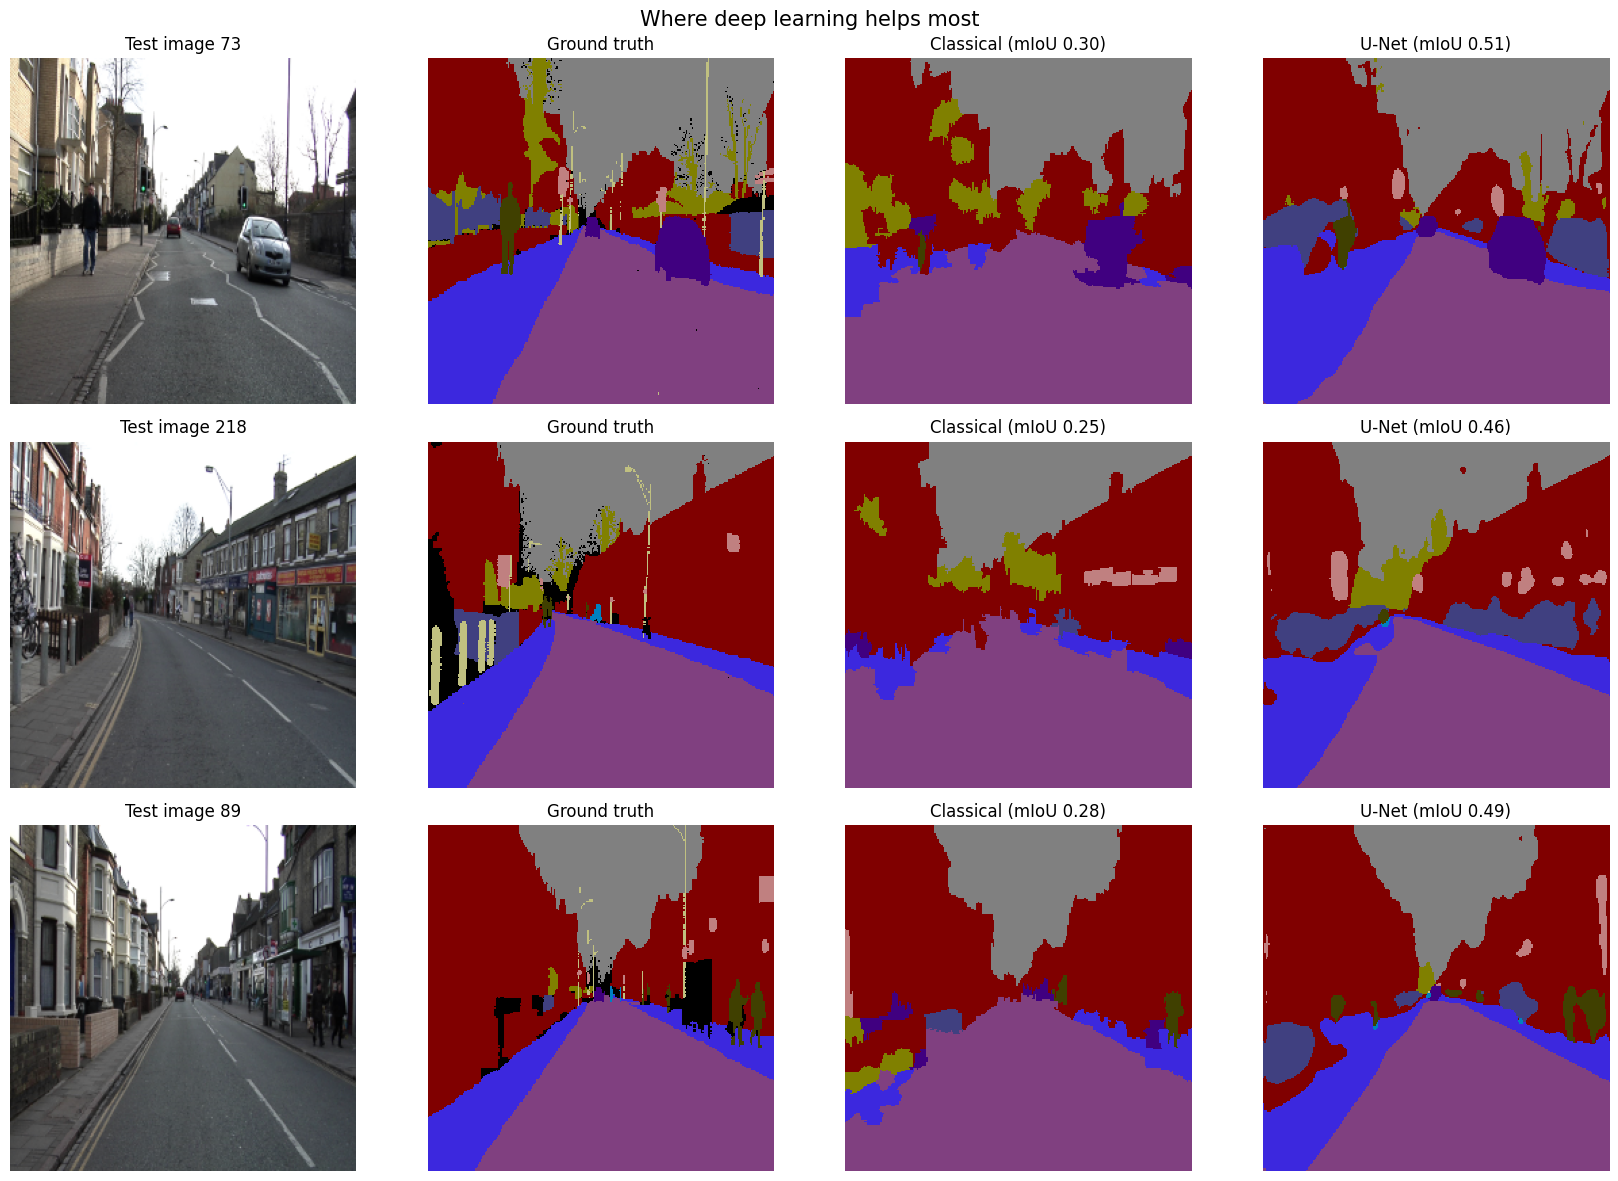

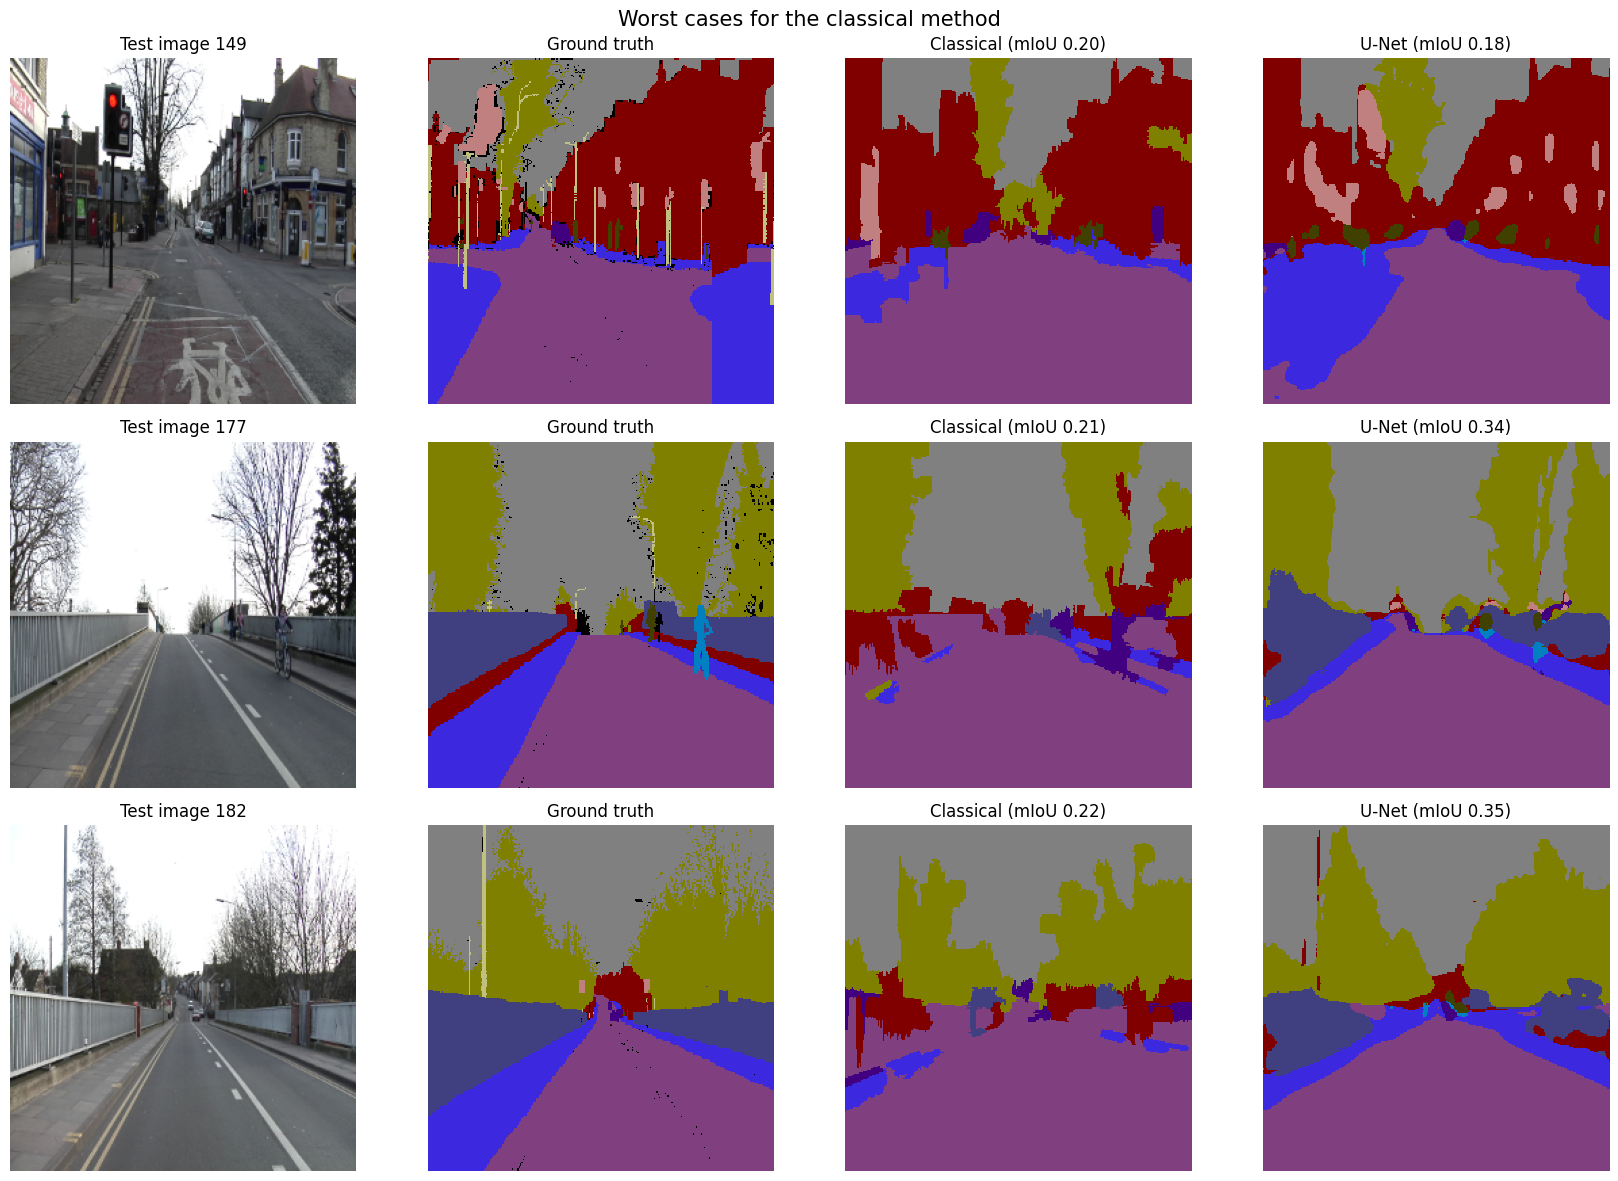

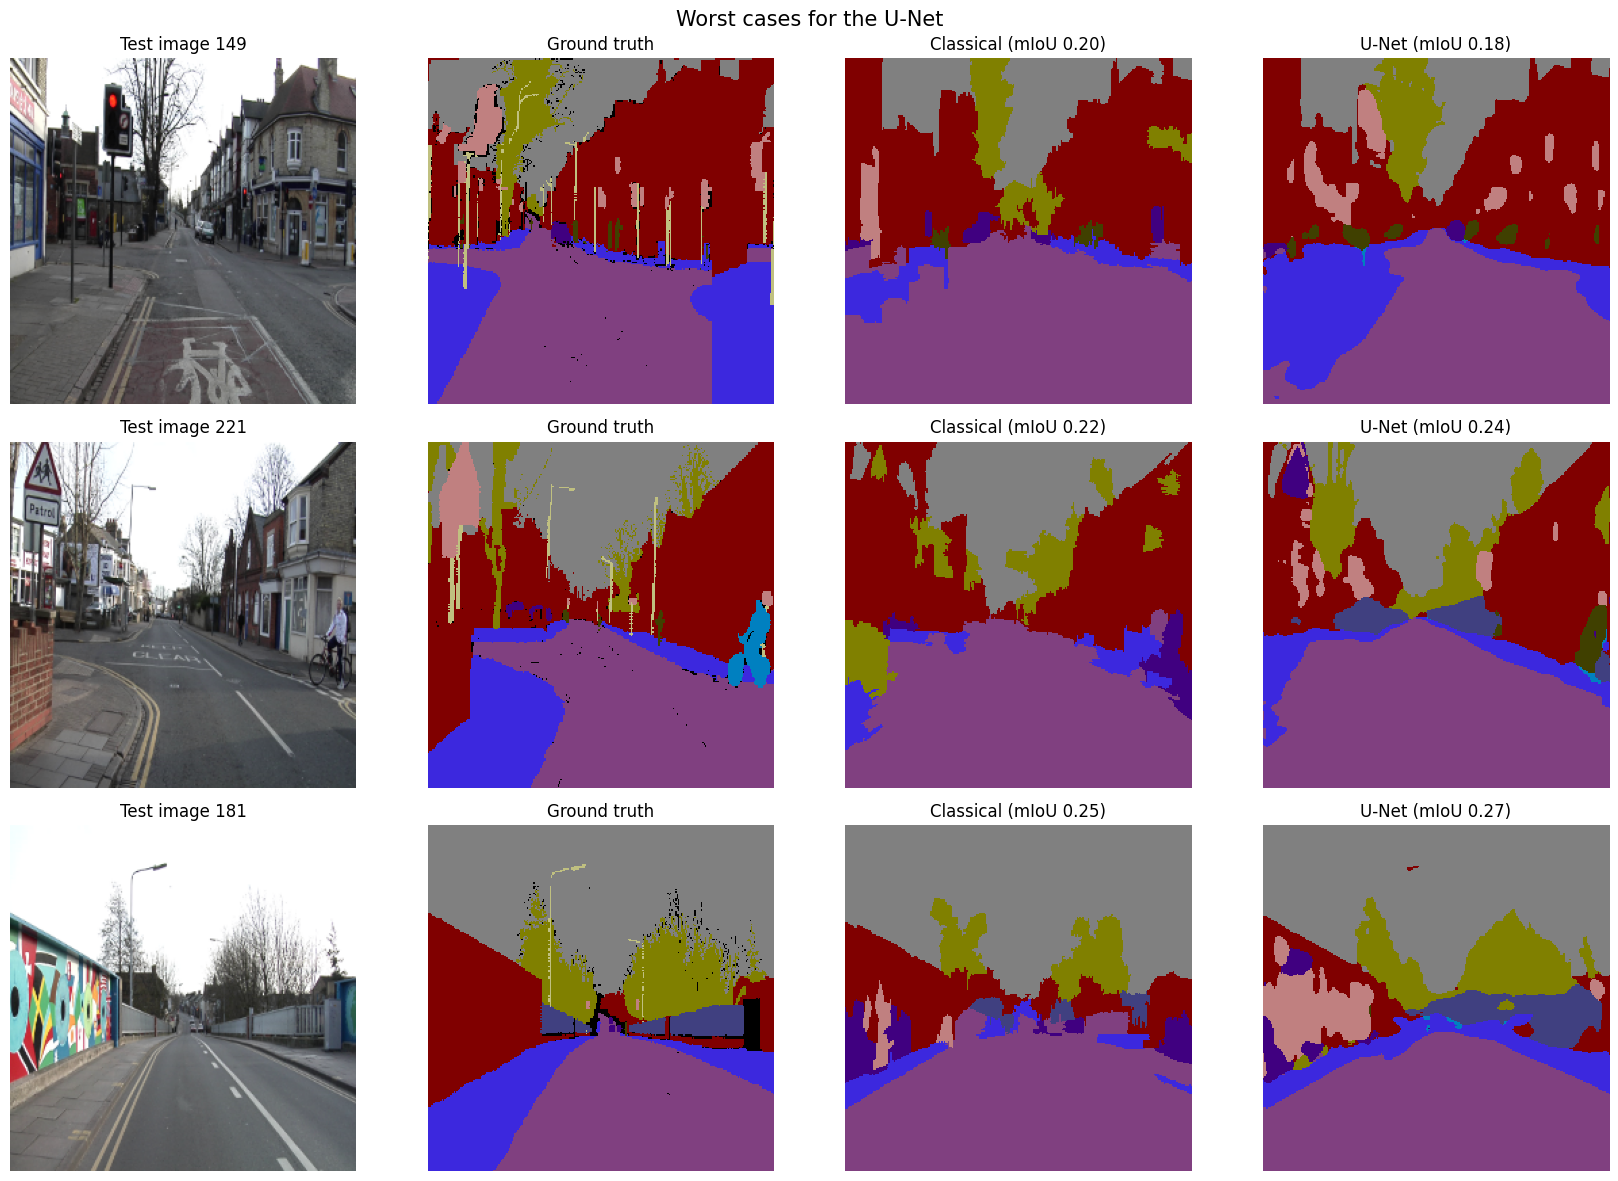

In [9]:
cl_per_image = per_image_miou(classical_preds, test_masks)
unet_per_image = per_image_miou(unet_preds, test_masks)

def show_comparison(ids, title):
    """Image | ground truth | classical | U-Net, for the same test images."""
    fig, axes = plt.subplots(len(ids), 4, figsize=(17, 4 * len(ids)))
    for r, idx in enumerate(ids):
        axes[r, 0].imshow(test_images[idx]); axes[r, 0].set_title(f"Test image {idx}"); axes[r, 0].axis("off")
        show_mask(axes[r, 1], test_masks[idx], "Ground truth")
        show_mask(axes[r, 2], classical_preds[idx], f"Classical (mIoU {cl_per_image[idx]:.2f})")
        show_mask(axes[r, 3], unet_preds[idx], f"U-Net (mIoU {unet_per_image[idx]:.2f})")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

both_good = np.argsort(-(cl_per_image + unet_per_image))[:3]
dl_gain = np.argsort(-(unet_per_image - cl_per_image))[:3]
cl_worst = np.argsort(cl_per_image)[:3]
unet_worst = np.argsort(unet_per_image)[:3]

print("Both good        :", list(both_good))
print("Biggest DL gain  :", list(dl_gain))
print("Worst classical  :", list(cl_worst))
print("Worst U-Net      :", list(unet_worst))

show_comparison(both_good, "Both methods work well")
show_comparison(dl_gain, "Where deep learning helps most")
show_comparison(cl_worst, "Worst cases for the classical method")
show_comparison(unet_worst, "Worst cases for the U-Net")

**Examples chosen for slide 9 (pros):**
- **161 – both work (0.46 / 0.52):** both find road, sky, buildings and pavement. The U-Net gives smooth, continuous regions; the classical method is patchier because each superpixel is classified alone, without looking at its neighbours.
- **62 – classical wins (0.52 / 0.45):** the U-Net predicts the red phone box as a sign (red, rectangular, at the edge of the pavement, like a sign), while the ground truth says building. The classical method, based on colour and position, puts it in building.
- **111 – U-Net wins (0.56 / 0.39):** the U-Net finds the whole pavement, the fence, the exact shape of the car and the pedestrian; the classical method predicts the pavement as road and splits the car. But the classical method finds the bollard in the foreground (pole), which the U-Net misses.

**Examples chosen for slide 10 (failures and limitations):**
- **149 – both fail (0.20 / 0.18):** busy street with many thin poles and a large pavement on the right, missed by both methods.
- **181 – the U-Net is fooled (0.25 / 0.27):** on the graffiti wall, the U-Net predicts signs and cars. Bright colours and unusual shapes look like what it learned for these classes: it fails on an appearance it never saw during training.
- **221 – the bicyclist is missed by both (0.22 / 0.24):** small and rare class (few training examples).

## 6. Robustness test: which method holds up when images get worse?
Our project asks how methods perform under different image conditions. We degrade the test images on purpose, at 3 levels each, and measure the mIoU of both methods. The models are **not retrained**: they learned on normal images and discover degraded ones, like a car camera at dusk or in bad weather.
- **Noise** (sensor noise in low light): Gaussian noise with σ = 10, 20, 30.
- **Darkness** (dusk, tunnel): brightness × 0.7, 0.5, 0.3.
- **Low contrast** (fog, backlight): contrast × 0.7, 0.5, 0.3 (pixels pulled towards the mean grey).
These match the problems measured in notebook 06 (dark images, test set darker than train).

In [10]:
def add_noise(img, sigma, seed=0):
    rng = np.random.default_rng(seed)
    return np.clip(img.astype(np.float64) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)

def darken(img, factor):
    return np.clip(img.astype(np.float64) * factor, 0, 255).astype(np.uint8)

def reduce_contrast(img, factor):
    mean = img.mean()
    return np.clip(mean + (img.astype(np.float64) - mean) * factor, 0, 255).astype(np.uint8)

DEGRADATIONS = [
    ("Noise", 10, lambda im: add_noise(im, 10)),
    ("Noise", 20, lambda im: add_noise(im, 20)),
    ("Noise", 30, lambda im: add_noise(im, 30)),
    ("Darkness", 0.7, lambda im: darken(im, 0.7)),
    ("Darkness", 0.5, lambda im: darken(im, 0.5)),
    ("Darkness", 0.3, lambda im: darken(im, 0.3)),
    ("Low contrast", 0.7, lambda im: reduce_contrast(im, 0.7)),
    ("Low contrast", 0.5, lambda im: reduce_contrast(im, 0.5)),
    ("Low contrast", 0.3, lambda im: reduce_contrast(im, 0.3)),
]

robust_rows = [{"Degradation": "Clean", "Level": "-", "Classical mIoU": cl_miou, "U-Net mIoU": unet_miou}]
for name, level, f in DEGRADATIONS:
    t0 = time.time()
    degraded = [f(img) for img in test_images]
    cl = evaluate(predict_classical(degraded), test_masks)[0]
    un = evaluate(predict_unet(degraded), test_masks)[0]
    robust_rows.append({"Degradation": name, "Level": level, "Classical mIoU": cl, "U-Net mIoU": un})
    print(f"{name:<13} {level:<4} classical = {cl:.3f} | U-Net = {un:.3f} ({time.time() - t0:.0f} s)")

df_robust = pd.DataFrame(robust_rows)
# Share of the clean score that is kept (100% = no loss)
df_robust["Classical kept (%)"] = (100 * df_robust["Classical mIoU"] / cl_miou).round(0)
df_robust["U-Net kept (%)"] = (100 * df_robust["U-Net mIoU"] / unet_miou).round(0)
df_robust.round(3)

Noise         10   classical = 0.213 | U-Net = 0.410 (52 s)
Noise         20   classical = 0.080 | U-Net = 0.307 (48 s)
Noise         30   classical = 0.050 | U-Net = 0.226 (46 s)
Darkness      0.7  classical = 0.252 | U-Net = 0.405 (41 s)
Darkness      0.5  classical = 0.220 | U-Net = 0.353 (41 s)
Darkness      0.3  classical = 0.185 | U-Net = 0.195 (40 s)
Low contrast  0.7  classical = 0.235 | U-Net = 0.380 (41 s)
Low contrast  0.5  classical = 0.141 | U-Net = 0.339 (41 s)
Low contrast  0.3  classical = 0.112 | U-Net = 0.297 (41 s)


,Degradation,Level,Classical mIoU,U-Net mIoU,Classical kept (%),U-Net kept (%)
0,Clean,-,0.333,0.434,100.0,100.0
1,Noise,10,0.213,0.410,64.0,95.0
2,Noise,20,0.080,0.307,24.0,71.0
3,Noise,30,0.050,0.226,15.0,52.0
4,Darkness,0.7,0.252,0.405,76.0,93.0
5,Darkness,0.5,0.220,0.353,66.0,81.0
6,Darkness,0.3,0.185,0.195,56.0,45.0
7,Low contrast,0.7,0.235,0.380,70.0,88.0
8,Low contrast,0.5,0.141,0.339,42.0,78.0
9,Low contrast,0.3,0.112,0.297,34.0,68.0


mIoU against the level of degradation (left = clean image). The slope shows how fast each method breaks down.

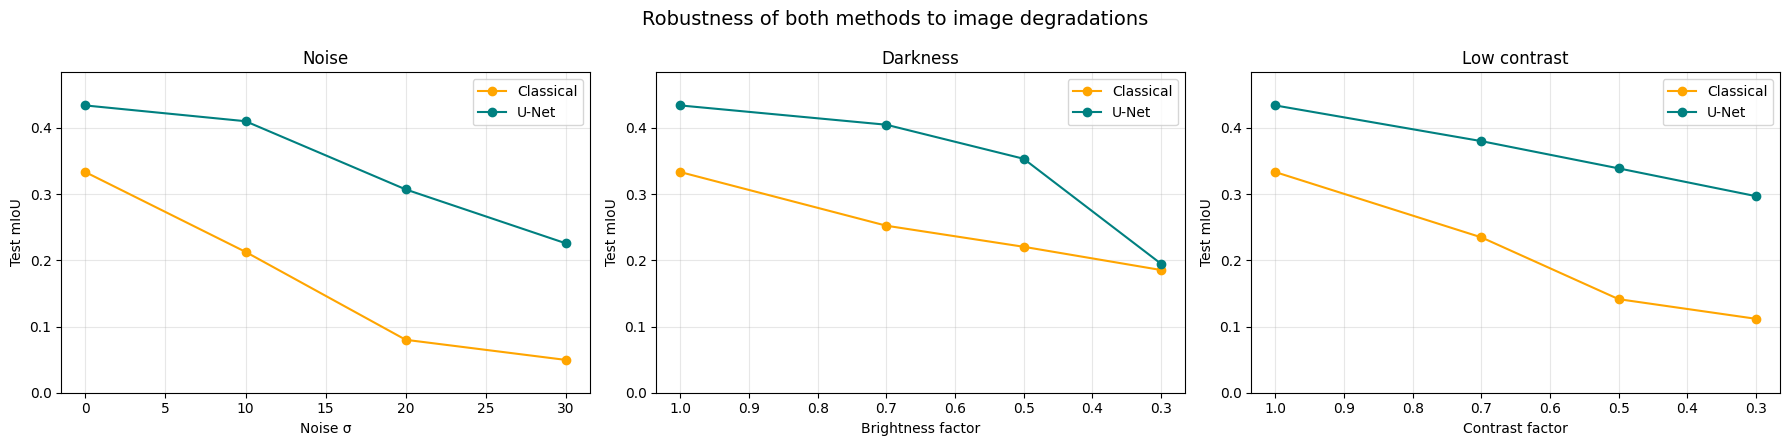

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name, clean_level, xlabel in [(axes[0], "Noise", 0, "Noise σ"),
                                      (axes[1], "Darkness", 1.0, "Brightness factor"),
                                      (axes[2], "Low contrast", 1.0, "Contrast factor")]:
    sub = df_robust[df_robust["Degradation"] == name]
    levels = [clean_level] + list(sub["Level"])
    ax.plot(levels, [cl_miou] + list(sub["Classical mIoU"]), "o-", color="orange", label="Classical")
    ax.plot(levels, [unet_miou] + list(sub["U-Net mIoU"]), "o-", color="teal", label="U-Net")
    if name != "Noise":
        ax.invert_xaxis()          # from clean (1.0) to strongly degraded (0.3)
    ax.set_title(name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Test mIoU")
    ax.set_ylim(0, max(unet_miou, cl_miou) + 0.05)
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle("Robustness of both methods to image degradations", fontsize=14)
plt.tight_layout()
plt.show()

Visual example: the same test image at the strongest level of each degradation, with both predictions.

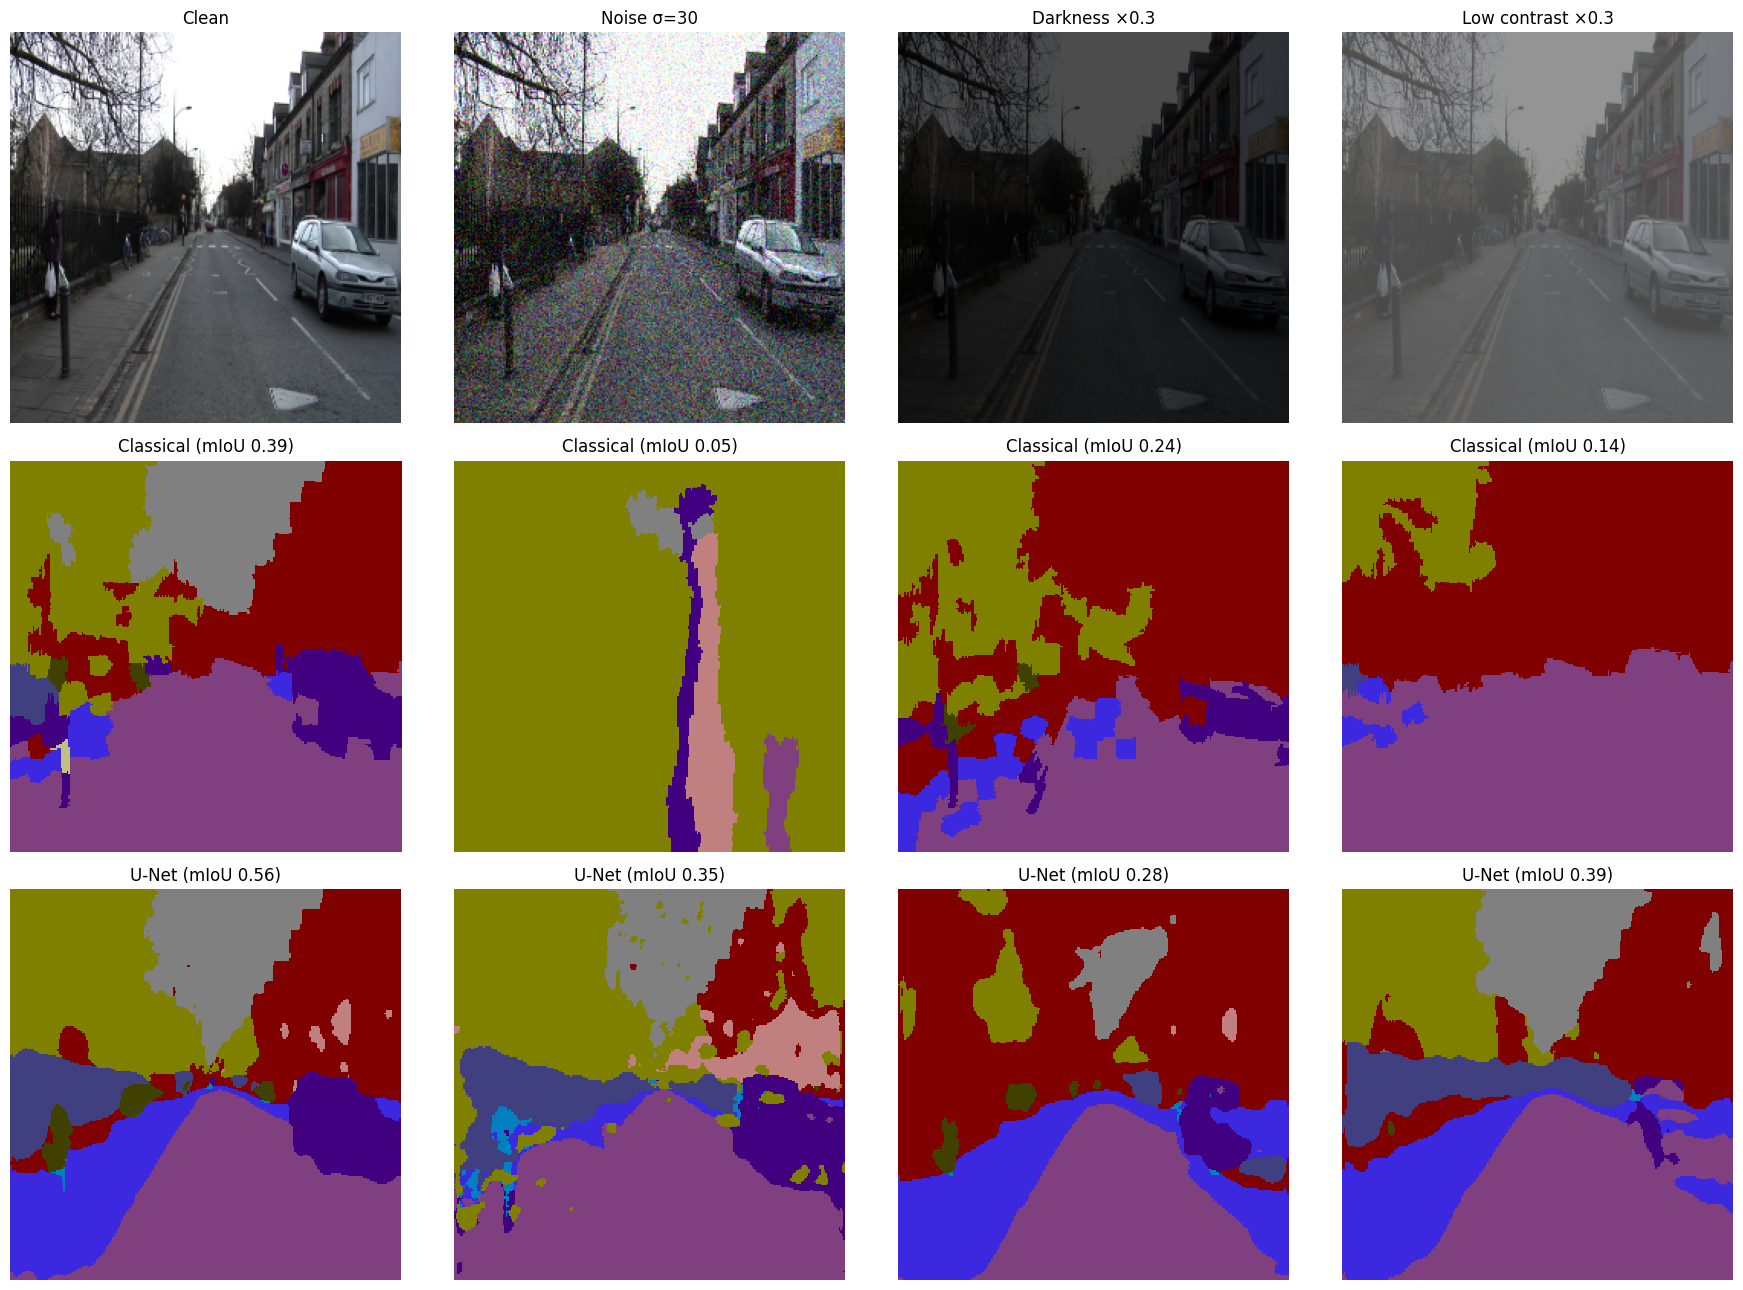

In [12]:
idx = 111   # image where both methods work well on the clean version
img = test_images[idx]
examples = [("Clean", img), ("Noise σ=30", add_noise(img, 30)),
            ("Darkness ×0.3", darken(img, 0.3)), ("Low contrast ×0.3", reduce_contrast(img, 0.3))]

fig, axes = plt.subplots(3, len(examples), figsize=(4.5 * len(examples), 13))
for c, (title, im) in enumerate(examples):
    cl_p = predict_classical([im])[0]
    un_p = predict_unet([im])[0]
    axes[0, c].imshow(im); axes[0, c].set_title(title); axes[0, c].axis("off")
    show_mask(axes[1, c], cl_p, f"Classical (mIoU {per_image_miou([cl_p], [test_masks[idx]])[0]:.2f})")
    show_mask(axes[2, c], un_p, f"U-Net (mIoU {per_image_miou([un_p], [test_masks[idx]])[0]:.2f})")
plt.tight_layout()
plt.show()

**What we learn from the robustness test:**
- **Noise: the classical method collapses** (24% of its clean score kept at σ=20, 15% at σ=30) while the U-Net keeps 52% at σ=30. On image 111, the noisy image is predicted almost entirely as "tree": noise creates texture everywhere, and our LBP, gradient and colour-std features describe texture, so for the Random Forest a very textured region is a tree. The U-Net keeps the structure of the scene.
- **Low contrast: same trend** (classical 34% kept at ×0.3, U-Net 68%). The classical method loses the sky, which becomes grey like the buildings.
- **Darkness: the U-Net holds up to ×0.5 (81% kept) but breaks at ×0.3** (0.195, 45% kept), almost down to the classical method (0.185, 56% kept). On image 111 it predicts almost everything as building. This is the only case where deep learning loses its advantage.

**Why:** the classical method relies on raw colour and texture values, so its features become meaningless as soon as these values change. The U-Net learned shapes and context, which are more robust. Its weak point is conditions it never saw during training: the brightness augmentation of notebook 02 is only ±10%, so an image at 30% brightness is completely outside what it knows. Together with the darker test set found in notebook 06, this suggests using a **stronger brightness augmentation** for the U-Net.

## 7. Can preprocessing rescue degraded images?
In notebook 06, filters did not help on normal images. Here we apply them **before** both models on the degraded images, as a restoration step: bilateral filter against noise, CLAHE against darkness and low contrast. The models are still not retrained.

In [13]:
def clahe_lab(img, clip=2.0, tile=8):
    """CLAHE on the lightness channel only, so the colours are not changed."""
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

def bilateral(img):
    return cv2.bilateralFilter(img, 9, 50, 50)

RESTORATION = [
    ("Noise", 20, lambda im: add_noise(im, 20), "Bilateral", bilateral),
    ("Noise", 30, lambda im: add_noise(im, 30), "Bilateral", bilateral),
    ("Darkness", 0.5, lambda im: darken(im, 0.5), "CLAHE", clahe_lab),
    ("Darkness", 0.3, lambda im: darken(im, 0.3), "CLAHE", clahe_lab),
    ("Low contrast", 0.5, lambda im: reduce_contrast(im, 0.5), "CLAHE", clahe_lab),
    ("Low contrast", 0.3, lambda im: reduce_contrast(im, 0.3), "CLAHE", clahe_lab),
]

rest_rows = []
for name, level, degrade, filt_name, filt in RESTORATION:
    t0 = time.time()
    restored = [filt(degrade(img)) for img in test_images]
    cl = evaluate(predict_classical(restored), test_masks)[0]
    un = evaluate(predict_unet(restored), test_masks)[0]
    before = df_robust[(df_robust["Degradation"] == name) & (df_robust["Level"] == level)].iloc[0]
    rest_rows.append({"Degradation": f"{name} {level}", "Filter": filt_name,
                      "Classical before": round(before["Classical mIoU"], 3), "Classical after": round(cl, 3),
                      "U-Net before": round(before["U-Net mIoU"], 3), "U-Net after": round(un, 3)})
    print(f"{name} {level} + {filt_name}: classical {before['Classical mIoU']:.3f} -> {cl:.3f} | "
          f"U-Net {before['U-Net mIoU']:.3f} -> {un:.3f} ({time.time() - t0:.0f} s)")

df_restore = pd.DataFrame(rest_rows)
df_restore

Noise 20 + Bilateral: classical 0.080 -> 0.232 | U-Net 0.307 -> 0.387 (46 s)
Noise 30 + Bilateral: classical 0.050 -> 0.146 | U-Net 0.226 -> 0.295 (50 s)
Darkness 0.5 + CLAHE: classical 0.220 -> 0.225 | U-Net 0.353 -> 0.400 (43 s)
Darkness 0.3 + CLAHE: classical 0.185 -> 0.216 | U-Net 0.195 -> 0.303 (44 s)
Low contrast 0.5 + CLAHE: classical 0.141 -> 0.171 | U-Net 0.339 -> 0.378 (42 s)
Low contrast 0.3 + CLAHE: classical 0.112 -> 0.130 | U-Net 0.297 -> 0.334 (42 s)


,Degradation,Filter,Classical before,Classical after,U-Net before,U-Net after
0,Noise 20,Bilateral,0.080,0.232,0.307,0.387
1,Noise 30,Bilateral,0.050,0.146,0.226,0.295
2,Darkness 0.5,CLAHE,0.220,0.225,0.353,0.400
3,Darkness 0.3,CLAHE,0.185,0.216,0.195,0.303
4,Low contrast 0.5,CLAHE,0.141,0.171,0.339,0.378
5,Low contrast 0.3,CLAHE,0.112,0.130,0.297,0.334


**What we learn from restoration:** preprocessing improves the results in all 6 cases, for both methods.
- **Bilateral against noise has the biggest effect:** the classical method triples at σ=20 (0.080 → 0.232, back to 70% of its clean score instead of 24%), and the U-Net goes from 0.307 to 0.387 (89% of its clean score). The filter removes the noise but keeps the edges, so the texture features of the classical method become meaningful again.
- **CLAHE fixes the collapse of the U-Net in the dark:** at brightness ×0.3 it goes from 0.195 to 0.303 (+55%) and is clearly ahead of the classical method again. CLAHE brings the image back to a brightness range close to the training images.
- **CLAHE helps the classical method much less** (+0.005 to +0.03): its HSV / Lab colour features already partly compensated for brightness.

## Conclusion
- **Clean images:** the U-Net is better (mIoU 0.434 vs 0.333), mostly thanks to context (pavement 0.22 → 0.65, fences, signs). For large typical classes (sky, building, car) hand-crafted features are almost enough. Thin objects (poles) fail for both, because they are only 1-2 pixels wide after the 256x256 resize.
- **Degraded images:** the classical method is much more fragile (noise, low contrast) because it relies on raw colour and texture values. The U-Net is more robust, except in conditions it never saw during training (very dark images), where it can drop to the level of the classical method.
- **Preprocessing:** useless on normal images (notebook 06), but very useful on degraded ones: bilateral filter against noise, CLAHE against darkness and low contrast. Preprocessing should be chosen according to the image conditions.
- **Improvements:** stronger brightness augmentation for the U-Net (the test set is darker than the training set), higher input resolution (e.g. the full 480x360 instead of 256x256) to keep thin objects, more training epochs (the U-Net was still improving at epoch 10).
- **Limits of this study:** each result comes from a single run, so differences of 1-2 mIoU points are not meaningful; only large gaps (U-Net vs classical, robustness to noise, effect of restoration) should be interpreted.